# EEG Research

This project studies EEG recorded during surgery from two subjects, 014 and 015. Each subject has three recordings:

- **Baseline** — before anesthesia
- **IFT** — anesthesia induction
- **Cut** — the first surgical incision

The sampling rate is 500 Hz. The goal of the project is to compare the EEG across these stages. This notebook only loads the full recordings and checks how much usable signal each file contains. Later steps can filter the signals and estimate their spectra. Those steps are not done here.

The incision files are named `surgery` on disk. The loading function maps that name to the Cut condition. There is no time column: each row is one sample, in recording order.


## 1. Data Loading and Initial Inspection

Analysis functions live in `eeg_analysis.py`. This notebook only calls them.

In [1]:
%matplotlib inline

from pathlib import Path
import importlib
import sys

project_dir = Path.cwd()
if str(project_dir) in sys.path:
    sys.path.remove(str(project_dir))
sys.path.insert(0, str(project_dir))

import eeg_analysis as eeg
eeg = importlib.reload(eeg)


Load every CSV in `data/`. Channel columns are detected from the header, so the number of EEG channels is not hardcoded. Missing values stay as NaN. Non-numeric cells, if any, are counted and left unchanged.

In [2]:
dataset = eeg.load_recordings(project_dir / "data")
print(f"Sampling rate: {dataset['sampling_rate_hz']} Hz")
print(f"Recordings: {len(dataset['recordings'])}")


Sampling rate: 500 Hz
Recordings: 6


The table below is one row per recording. Duration is the number of samples divided by 500 Hz. A channel "with data" has at least one sample. Channels listed as completely missing are NaN from start to end.

In [3]:
summary = eeg.recording_summary(dataset)
summary_view = summary.copy()
summary_view["duration_seconds"] = summary_view["duration_seconds"].round(3)
summary_view["missing_percent"] = summary_view["missing_percent"].round(3)
summary_view


,subject_id,condition,source_file,n_samples,duration_seconds,n_channels,n_channels_with_data,n_missing_values,missing_percent,completely_missing_channels
0,014,Baseline,014_baseline_filtered.csv,15001,30.002,18,16,30002,11.111,"Ch17, Ch18"
1,014,IFT,014_IFT_filtered.csv,15921,31.842,18,16,31884,11.126,"Ch17, Ch18"
2,014,Cut,014_surgery_filtered_labelled.csv,150001,300.002,18,16,316662,11.728,"Ch17, Ch18"
3,015,Baseline,015_baseline_filtered.csv,15001,30.002,18,16,30002,11.111,"Ch17, Ch18"
4,015,IFT,015_IFT_filtered.csv,50711,101.422,18,15,152366,16.692,"Ch10, Ch17, Ch18"
5,015,Cut,015_surgery_filtered_labelled.csv,150001,300.002,18,16,472310,17.493,"Ch17, Ch18"


Missing-value percentage for each channel. A value of 100 means the channel is empty in that recording. A value of 0 means every sample is present.

In [4]:
missing_by_channel = eeg.missing_percent_by_channel(dataset)
missing_by_channel.round(3)


,Ch1,Ch2,Ch3,Ch4,Ch5,Ch6,Ch7,Ch8,Ch9,Ch10,Ch11,Ch12,Ch13,Ch14,Ch15,Ch16,Ch17,Ch18
014_Baseline,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,100.0,100.0
014_IFT,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.264,100.0,100.0
014_Cut,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,11.107,100.0,100.0
015_Baseline,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,100.0,100.0
015_IFT,0.000,0.000,0.000,0.014,0.000,0.000,0.000,0.000,0.000,100.000,0.000,0.000,0.446,0.000,0.000,0.000,100.0,100.0
015_Cut,15.078,14.472,4.599,0.151,10.761,6.591,3.963,0.371,8.343,3.193,13.369,3.579,1.025,11.527,7.649,10.202,100.0,100.0


The same percentages are shown below as one heatmap, so the six recordings can be compared without a separate plot per channel.

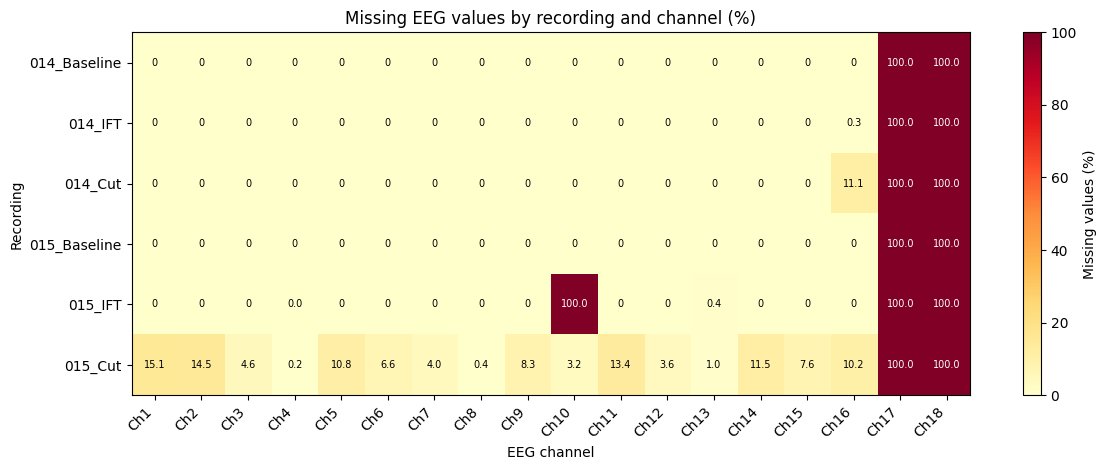

In [5]:
fig = eeg.plot_missing_percentages(dataset)


### How to read these results

All six files contain the same 18 channel columns, `Ch1`–`Ch18`. Missing samples are stored as NaN.

**How long each recording is**

| Recording | Samples | Duration |
| --- | ---: | ---: |
| 014 Baseline | 15,001 | 30.002 s |
| 014 IFT | 15,921 | 31.842 s |
| 014 Cut | 150,001 | 300.002 s |
| 015 Baseline | 15,001 | 30.002 s |
| 015 IFT | 50,711 | 101.422 s |
| 015 Cut | 150,001 | 300.002 s |

The two Cut recordings are about ten times longer than the baselines. The two IFT recordings also differ in length (31.842 s versus 101.422 s). Comparisons later in the project should keep this in mind.

**Where the missing values are**

`Ch17` and `Ch18` are completely empty in every recording. They hold no usable signal and are the natural candidates to drop before any later analysis. Because those two channels are 2 of 18 columns, even a recording that is otherwise complete is 11.111% missing.

Beyond those two channels:

- Both **Baseline** recordings are complete on `Ch1`–`Ch16`. Sixteen channels contain data.
- **014 IFT** is almost complete on `Ch1`–`Ch16`. The only extra gap is 42 samples on `Ch16` (0.264%). Sixteen channels contain data.
- **014 Cut** is complete on `Ch1`–`Ch15`. `Ch16` is missing 11.107% of its samples. Sixteen channels contain data.
- **015 IFT** has a third empty channel: `Ch10` is missing for the whole recording. `Ch4` has 7 missing samples (0.014%) and `Ch13` has 226 (0.446%). Fifteen channels contain data.
- **015 Cut** is the only recording with gaps spread across `Ch1`–`Ch16`. Every one of those channels is partly missing, from 0.151% (`Ch4`) to 15.078% (`Ch1`). The larger gaps are on `Ch1` (15.078%), `Ch2` (14.472%), `Ch11` (13.369%), `Ch14` (11.527%), `Ch5` (10.761%), and `Ch16` (10.202%). `Ch17` and `Ch18` are still the only channels that are completely empty, so sixteen channels still contain some data. The overall missing rate for this file is 17.493%.

Missing data is therefore concentrated, not uniform. It sits in two channels that are empty everywhere (`Ch17`, `Ch18`), in one extra empty channel for 015 IFT (`Ch10`), in a moderate `Ch16` gap for 014 Cut, and in widespread partial gaps for 015 Cut. The other recordings are effectively complete once `Ch17` and `Ch18` are set aside.


## 3. Missing Data Imputation

Later spectral analysis needs a value at every time point that we choose to keep. The missing stretches found in Step 2 are not all the same length, so they are not all filled in the same way.

This section reconstructs only the gaps that still have observed samples on both sides. The original recordings are not changed. Each result below is a copy.


### 3.1 Imputation Methods

A single missing sample is filled by linear interpolation. The new value lies on the straight line between the nearest observed sample before the gap and the nearest observed sample after it.

Short gaps, from 2 to 50 samples, are filled with PCHIP (`scipy.interpolate.PchipInterpolator`). PCHIP is a shape-preserving interpolant. It follows the observed samples without the overshoot that a cubic spline can produce.

Medium gaps, from 51 to 250 samples (102–500 ms), are also filled with PCHIP, but only as a provisional baseline. A gap of that length can hide real EEG changes, so these values are not treated as recovered signal.

Long gaps, more than 250 samples, are left as NaN. A completely missing channel is also left as NaN and stays out of later analysis of that channel. The cutoffs of 1, 50, and 250 samples are choices for this project. They are not thresholds taken from the papers.


In [6]:
import matplotlib.pyplot as plt
import pandas as pd

gap_summary, gap_details, gap_fig = eeg.classify_missing_gaps(dataset)
plt.close(gap_fig)

imputed_recordings = {}
gap_logs = {}
summary_rows = []
for record in gap_summary.itertuples(index=False):
    key = f"{record.subject_id}_{record.condition}"
    recording = dataset["recordings"][key]
    rows = gap_details[
        (gap_details["subject_id"] == record.subject_id)
        & (gap_details["condition"] == record.condition)
    ]
    imputed, log, summary = eeg.impute_recording(recording["eeg"], rows)
    imputed_recordings[key] = imputed
    gap_logs[key] = log
    summary_rows.append(summary)

imputation_summary = pd.DataFrame(summary_rows)


In [7]:
imputation_summary


,subject_id,condition,n_missing_original,n_linear_samples,n_pchip_samples,n_missing_remaining,n_skipped_gaps,n_provisional_gaps
0,014,Baseline,30002,0,0,30002,2,0
1,014,IFT,31884,0,42,31842,2,0
2,014,Cut,316662,12,16648,300002,2,92
3,015,Baseline,30002,0,0,30002,2,0
4,015,IFT,152366,0,233,152133,3,3
5,015,Cut,472310,183,132114,340013,117,712


### 3.2 What the Figure Shows

The figure uses 014 Cut, channel `Ch16`, because that channel contains both a short gap and a medium gap. The black line is the original signal, so it breaks where samples were missing. The red line is the interpolated segment, and the shaded band marks the samples that were filled. The lower panel is a provisional medium-gap reconstruction, not a checked recovery of the EEG.


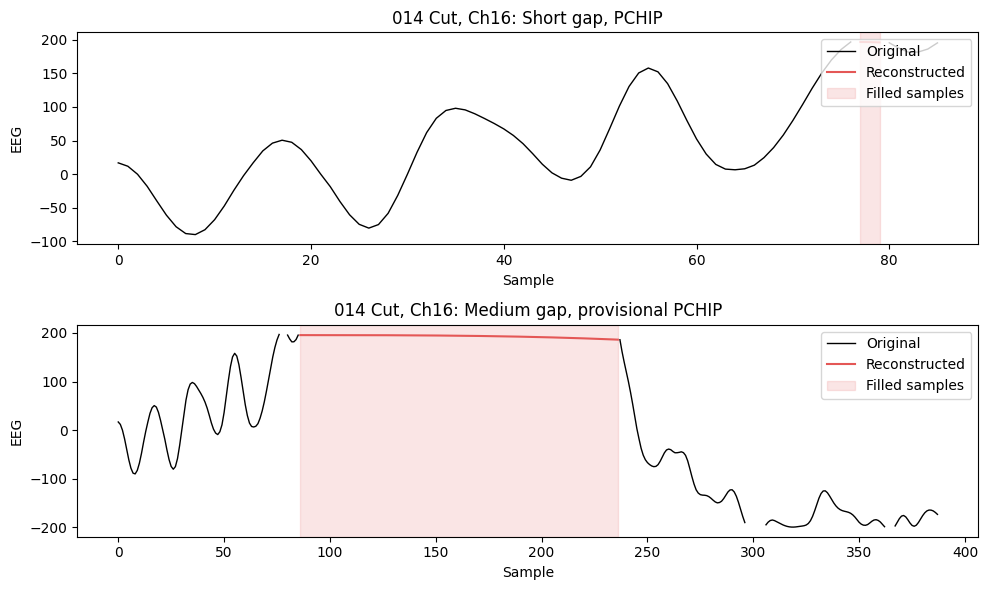

In [8]:
example_fig = eeg.plot_imputation_example(
    dataset["recordings"]["014_Cut"]["eeg"],
    imputed_recordings["014_Cut"],
    gap_logs["014_Cut"],
)


### 3.3 Results and Interpretation

No originally observed sample was changed. Filled samples plus the samples that remain missing equal the original missing-sample count in every recording.

Both baseline recordings had nothing to fill. Their only missing data are `Ch17` and `Ch18`, which stay empty (30,002 missing samples in each file).

014 IFT: 42 samples in two short gaps on `Ch16` were filled with PCHIP. The two empty channels remain missing.

014 Cut: 12 single-sample gaps were filled by linear interpolation, and 16,648 samples were filled with PCHIP. Those PCHIP samples include 92 medium gaps, which are provisional. The only skipped gaps are `Ch17` and `Ch18`. Every partial gap on `Ch16` was filled. 300,002 samples remain missing, all of them in the two empty channels.

015 IFT: 233 samples were filled with PCHIP. Three of those gaps are provisional medium gaps, on `Ch13`. `Ch10`, `Ch17`, and `Ch18` stay empty, so 152,133 samples remain missing.

015 Cut has the largest reconstruction and the largest exclusion. Linear interpolation filled 183 single samples. PCHIP filled 132,114 samples, including 712 provisional medium gaps. The 115 long gaps were not filled. Together with `Ch17` and `Ch18`, they leave 340,013 samples missing. Those long gaps are the ones that should not be passed to a spectral estimate as if they were real EEG.

The filled values, especially the medium gaps, still need a quality check. They are interpolated numbers, not measurements.


### 3.4 Methodology and Limitations

The 2026 scoping review of EEG gap imputation is the reason more than one reconstruction method is used, and the reason gap length decides which method is tried. The 2022 SRI-EEG paper is the reason the original missing locations are kept in the gap log. This step does not implement the SRI-EEG model, and it does not use a neural network.

Linear interpolation and PCHIP do not guarantee that the missing EEG has been recovered. They only draw a curve through the samples that remain. Medium gaps are a provisional baseline for that reason. The next step is to compare those medium-gap PCHIP values with a multivariate autoregressive reconstruction, where that comparison is feasible, before any frequency-domain analysis.


### 3.5 Remaining missing values

The heatmap below uses the same display as the first inspection, applied to the recordings after imputation. A cell is the percentage of samples that are still missing. Filled gaps become 0. Long gaps and completely empty channels stay above 0.


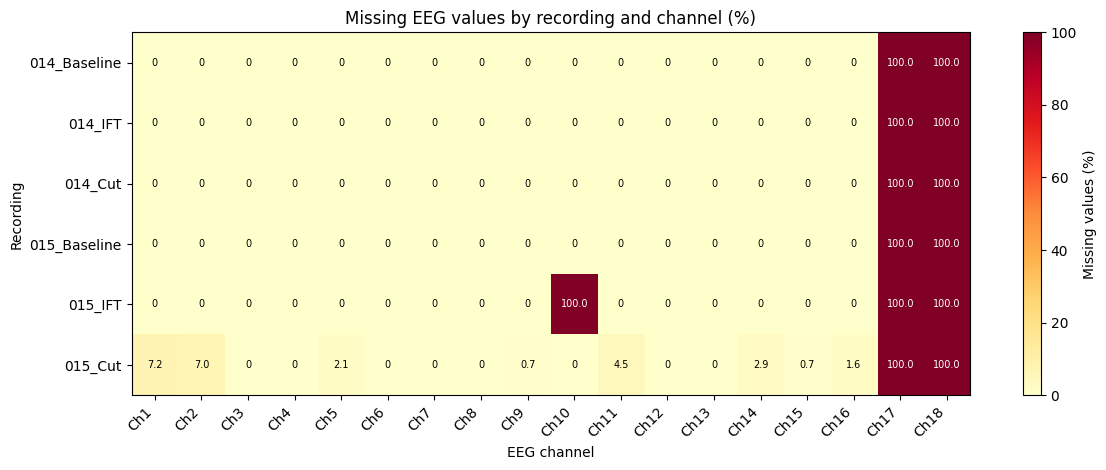

In [9]:
imputed_dataset = {
    "sampling_rate_hz": dataset["sampling_rate_hz"],
    "recordings": {
        key: {
            "subject_id": dataset["recordings"][key]["subject_id"],
            "condition": dataset["recordings"][key]["condition"],
            "eeg": imputed,
        }
        for key, imputed in imputed_recordings.items()
    },
}
missing_after_fig = eeg.plot_missing_percentages(imputed_dataset)


## 4. Band-pass Filtering (1–40 Hz)

### 4.1 Objective

Slow changes below 1 Hz are mostly baseline drift. They move the whole trace up and down without being part of the rhythms we will analyze later. Activity above 40 Hz is mostly high-frequency noise relative to those rhythms. A band-pass filter reduces both before any frequency analysis.


### 4.2 Method

The filter is a 4th-order Butterworth band-pass from 1 Hz to 40 Hz, applied at the 500 Hz sampling rate. `sosfiltfilt` runs that filter forward and then backward. The backward pass removes the time shift, so peaks stay at the same sample.

Filtering changes the value of each sample inside a continuous stretch. It does not delete samples, and it does not fill missing ones. Each run of finite samples is filtered on its own. A NaN gap is not crossed. A run shorter than the padding this filter needs is left at its Step 3 values. A 4th-order Butterworth does not stop exactly at 1 Hz and 40 Hz, so some energy just outside the band remains.


In [10]:
filtered_recordings = {}
filter_counts = []
for key, imputed in imputed_recordings.items():
    filtered, counts = eeg.bandpass_recording(imputed)
    filtered_recordings[key] = filtered
    filter_counts.append({"recording": key, **counts})

filter_summary = pd.DataFrame(filter_counts)
filter_summary


,recording,n_segments_filtered,n_segments_too_short
0,014_Baseline,16,0
1,014_IFT,16,0
2,014_Cut,16,0
3,015_Baseline,16,0
4,015_IFT,15,0
5,015_Cut,114,17


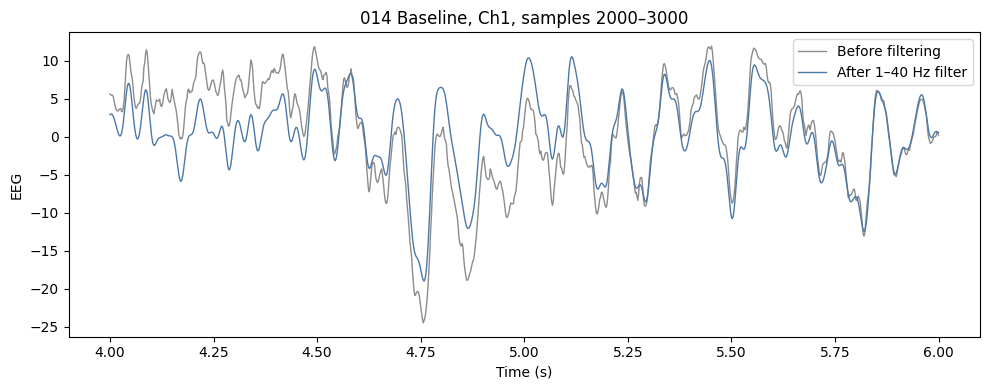

In [11]:
import matplotlib.pyplot as plt
import numpy as np

channel = "Ch1"
start, end = 2000, 3000
time_seconds = np.arange(start, end + 1) / dataset["sampling_rate_hz"]
before = imputed_recordings["014_Baseline"][channel].iloc[start:end + 1]
after = filtered_recordings["014_Baseline"][channel].iloc[start:end + 1]

fig, axis = plt.subplots(figsize=(10, 4))
axis.plot(time_seconds, before, color="0.55", linewidth=1, label="Before filtering")
axis.plot(time_seconds, after, color="#4C78A8", linewidth=1, label="After 1–40 Hz filter")
axis.set_xlabel("Time (s)")
axis.set_ylabel("EEG")
axis.set_title("014 Baseline, Ch1, samples 2000–3000")
axis.legend()
fig.tight_layout()


### 4.3 Interpretation

On this two-second stretch of 014 Baseline, `Ch1`, the filtered line is smoother than the imputed line. The large slow wander is smaller, and the fastest jitter is smaller, because those parts of the signal sit outside 1–40 Hz.

The cutoff is not a hard wall. A 4th-order Butterworth only attenuates frequencies outside the passband, so a little energy below 1 Hz and above 40 Hz remains. The band that is kept still covers the rhythms planned for the later frequency analysis.

Removing everything below 1 Hz also removes slow EEG activity that can be physiologically real. That is a limit of this choice, not a claim that those slow components were only drift. In 015 Cut, 17 finite segments were shorter than the filter padding, so they were left unfiltered. Long gaps and `Ch17` and `Ch18` are still NaN.


## 5. Signal Analysis

The metrics below use the filtered recordings from Step 4. Each function lives in `eeg_analysis.py`. This notebook calls those functions and shows the returned numbers.

An epoch is 10 seconds (5000 samples) and does not overlap the next one. It is cut only from a stretch where every kept channel is finite for the whole 10 seconds. A stretch is not joined across a NaN gap. Channels that are missing for the entire file are dropped. In a kept channel, at most 5% of the epoch may be imputed. Imputed means the sample was NaN in the original file and finite after Step 3.

A recording is READY when every 10-second block passes, PARTIAL when some blocks are dropped, and NOT READY when none pass. Metrics are computed only on the accepted epochs.

### 5.1 Data Readiness

The table has one row per recording. Duration is the full file length. The missing percentages use every cell in the file, including channels that are empty from start to finish. Usable epochs are the blocks that enter the metrics. Excluded epochs are 10-second blocks with too much imputation, plus finite stretches shorter than 10 seconds.

In [12]:
readiness_rows = []
analysis_epochs = []
for record in gap_summary.itertuples(index=False):
    key = f"{record.subject_id}_{record.condition}"
    report, epochs = eeg.prepare_recording(
        dataset["recordings"][key]["eeg"],
        imputed_recordings[key],
        filtered_recordings[key],
        record.subject_id,
        record.condition,
    )
    readiness_rows.append(report)
    analysis_epochs.extend(epochs)

readiness = pd.DataFrame(readiness_rows)
readiness


,subject_id,condition,duration_seconds,channels_used,channels_excluded,original_missing_percent,imputed_percent,remaining_missing_percent,n_usable_epochs,n_excluded_epochs,exclusion_reason,status
0,014,Baseline,30.002,"Ch1, Ch2, Ch3, Ch4, Ch5, Ch6, Ch7, Ch8, Ch9, C...","Ch17, Ch18",11.111111,0.000000,11.111111,3,0,None,READY
1,014,IFT,31.842,"Ch1, Ch2, Ch3, Ch4, Ch5, Ch6, Ch7, Ch8, Ch9, C...","Ch17, Ch18",11.125767,0.014656,11.111111,3,0,None,READY
2,014,Cut,300.002,"Ch1, Ch2, Ch3, Ch4, Ch5, Ch6, Ch7, Ch8, Ch9, C...","Ch17, Ch18",11.728144,0.617033,11.111111,17,13,13 epochs had more than 5% imputed samples in ...,PARTIAL
3,015,Baseline,30.002,"Ch1, Ch2, Ch3, Ch4, Ch5, Ch6, Ch7, Ch8, Ch9, C...","Ch17, Ch18",11.111111,0.000000,11.111111,3,0,None,READY
4,015,IFT,101.422,"Ch1, Ch2, Ch3, Ch4, Ch5, Ch6, Ch7, Ch8, Ch9, C...","Ch10, Ch17, Ch18",16.692193,0.025526,16.666667,10,0,None,READY
5,015,Cut,300.002,"Ch1, Ch2, Ch3, Ch4, Ch5, Ch6, Ch7, Ch8, Ch9, C...","Ch17, Ch18",17.492846,4.899856,12.592990,17,32,5 epochs had more than 5% imputed samples in a...,PARTIAL


Four recordings are READY: both baselines, 014 IFT, and 015 IFT. Each has a continuous finite stretch on the kept channels, and no accepted block exceeds the 5% imputation limit.

014 Baseline and 015 Baseline are 30.002 seconds, with 11.111% missing only because Ch17 and Ch18 are empty. Nothing was imputed. Each gives 3 epochs, and the leftover sample is shorter than 10 seconds, so it is not an epoch.

014 IFT is 31.842 seconds. Original missingness is 11.126%, of which 0.015% was imputed on Ch16. Those two short gaps start at sample 15401, after the third epoch ends at sample 15000, so they sit in the leftover tail. The recording stays READY with 3 epochs. Remaining missingness is 11.111%, the two empty channels.

015 IFT is 101.422 seconds. Ch10, Ch17, and Ch18 are empty, which is why 16.667% of the filtered file is still missing. The six partial gaps were filled and none of them reaches 5% of a 10-second epoch (5% is 250 samples; the longest filled gap is 71 samples). Ten epochs are READY.

014 Cut is PARTIAL. The file is 300.002 seconds. Ch17 and Ch18 are excluded. Seventeen epochs pass and 13 are excluded because Ch16 imputation is above 5% in those blocks. Original missingness is 11.728%, imputed samples are 0.617%, and the two empty channels leave 11.111% missing after filtering.

015 Cut is PARTIAL. Original missingness is 17.493%. Imputation fills 4.900%, and 12.593% remains missing because long gaps and Ch17 and Ch18 were left as NaN. Seventeen epochs pass. Five epochs fail the 5% rule, and 27 finite stretches are shorter than 10 seconds, so they cannot form an epoch. No recording is NOT READY, so every file contributes some epochs. The Cut results describe only the accepted blocks.

### 5.2 Power Spectrum and Band Power

Welch's method estimates the power spectrum of each channel in each accepted epoch. The segment length is 1000 samples, so the frequency bins are 0.5 Hz wide. Overlap is SciPy's default, half of that segment. Absolute power is the area of a band. Relative power divides that area by the sum of the five bands.

The bands do not overlap. A shared boundary goes to the higher band: delta 1–4 Hz, theta 4–8 Hz, alpha 8–13 Hz, beta 13–30 Hz, and gamma 30–40 Hz. The 40 Hz bin stays in gamma. The spectrum plot averages channels and epochs. The bar chart uses the same average of relative power.

band                  Delta  Theta  Alpha   Beta  Gamma
subject_id condition                                   
014        Baseline   0.271  0.138  0.349  0.208  0.034
           Cut        0.418  0.216  0.261  0.098  0.006
           IFT        0.234  0.168  0.354  0.233  0.011
015        Baseline   0.081  0.054  0.559  0.284  0.021
           Cut        0.235  0.159  0.333  0.263  0.010
           IFT        0.384  0.163  0.227  0.217  0.010

,subject_id,condition,band,relative_power
0,014,Baseline,Alpha,0.349
1,014,Cut,Delta,0.418
2,014,IFT,Alpha,0.354
3,015,Baseline,Alpha,0.559
4,015,Cut,Alpha,0.333
5,015,IFT,Delta,0.384


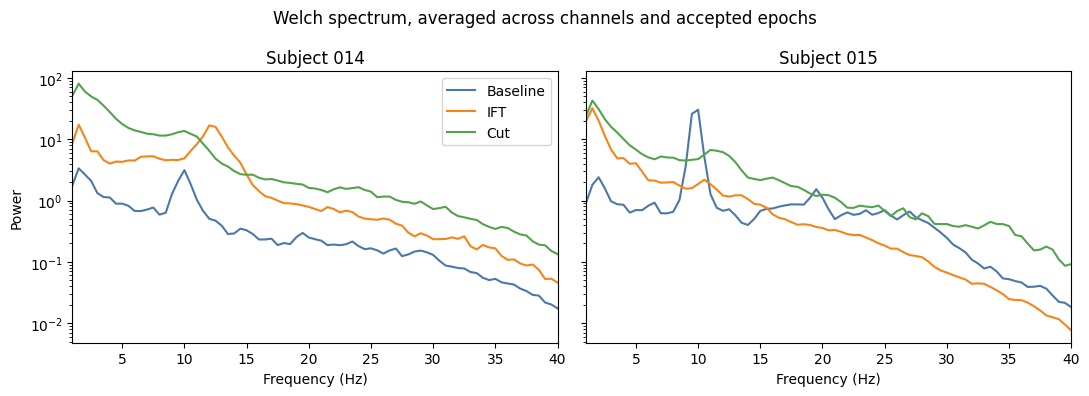

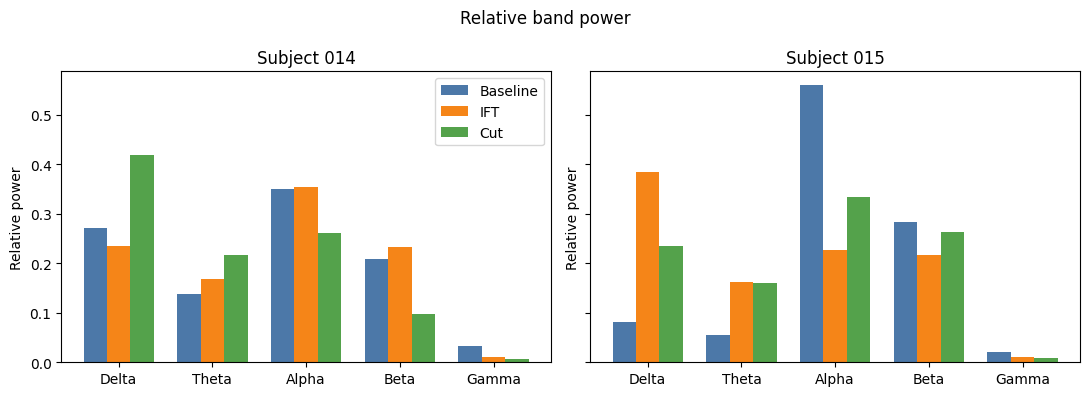

In [13]:
import numpy as np
from IPython.display import display

band_power, spectra = eeg.welch_band_power(analysis_epochs)
band_order = ["Delta", "Theta", "Alpha", "Beta", "Gamma"]
condition_order = ["Baseline", "IFT", "Cut"]
condition_colors = {"Baseline": "#4C78A8", "IFT": "#F58518", "Cut": "#54A24B"}

mean_bands = (
    band_power.groupby(["subject_id", "condition", "band"], as_index=False)["relative_power"].mean()
)
band_table = mean_bands.pivot(index=["subject_id", "condition"], columns="band", values="relative_power")
band_table = band_table[band_order].round(3)
dominant_band = (
    mean_bands.sort_values("relative_power", ascending=False)
    .groupby(["subject_id", "condition"], as_index=False)
    .first()[["subject_id", "condition", "band", "relative_power"]]
)
dominant_band["relative_power"] = dominant_band["relative_power"].round(3)

display(band_table)
display(dominant_band)

mean_psd = spectra.groupby(["subject_id", "condition", "frequency"], as_index=False)["power"].mean()
fig, axes = plt.subplots(1, 2, figsize=(11, 4), sharey=True)
for ax, subject in zip(axes, ["014", "015"]):
    for condition in condition_order:
        part = mean_psd[(mean_psd["subject_id"] == subject) & (mean_psd["condition"] == condition)]
        ax.semilogy(part["frequency"], part["power"], color=condition_colors[condition], label=condition)
    ax.set_title(f"Subject {subject}")
    ax.set_xlabel("Frequency (Hz)")
    ax.set_xlim(1, 40)
axes[0].set_ylabel("Power")
axes[0].legend()
fig.suptitle("Welch spectrum, averaged across channels and accepted epochs")
fig.tight_layout()

fig, axes = plt.subplots(1, 2, figsize=(11, 4), sharey=True)
positions = np.arange(len(band_order))
width = 0.25
for ax, subject in zip(axes, ["014", "015"]):
    for offset, condition in enumerate(condition_order):
        part = mean_bands[(mean_bands["subject_id"] == subject) & (mean_bands["condition"] == condition)]
        heights = part.set_index("band").loc[band_order, "relative_power"]
        ax.bar(
            positions + (offset - 1) * width,
            heights,
            width,
            color=condition_colors[condition],
            label=condition,
        )
    ax.set_xticks(positions, band_order)
    ax.set_title(f"Subject {subject}")
    ax.set_ylabel("Relative power")
axes[0].legend()
fig.suptitle("Relative band power")
fig.tight_layout()


Alpha is the largest band in four of the six recordings. In 014 Baseline its relative power is 0.349, and in 014 IFT it is 0.354. 015 Baseline is more concentrated in alpha, at 0.559. 015 Cut is also led by alpha, at 0.333.

The two exceptions are the later recordings that shift toward slower activity. 014 Cut is led by delta at 0.418, with alpha down to 0.261 and beta down to 0.098. 015 IFT is led by delta at 0.384, with alpha at 0.227. Gamma is the smallest band in every recording, from 0.034 in 014 Baseline to 0.006 in 014 Cut. That is consistent with the 40 Hz filter edge, which attenuates the top of this band.

These are averages over channels and over the accepted epochs of each file. They describe these two subjects. They are not a test on a larger population.

### 5.3 Spectral Exponent

The spectral exponent describes the slope of the power spectrum in log-log space. A larger positive value means power falls more steeply as frequency rises. The fit uses `specparam` in fixed aperiodic mode, after the Welch spectrum has been averaged across epochs within each channel. Peaks are included in the model so that a narrow peak, such as alpha, is not forced into the slope.

The same average spectrum is fit three times: 1–40 Hz, 1–20 Hz, and 20–40 Hz. The dashed curves in the figure are the 1–40 Hz aperiodic fits, averaged across channels for display. The table keeps one exponent per channel. This number is not a consciousness measure. The 1 Hz and 40 Hz filter edges can bend the fit, and 20 Hz belongs to both of the split ranges.

frequency_range       1-20 Hz  1-40 Hz  20-40 Hz
subject_id condition                            
014        Baseline     0.801    1.325     3.746
           Cut          1.332    2.118     5.550
           IFT          0.911    1.733     5.219
015        Baseline     0.028    1.100     5.418
           Cut          0.935    1.790     5.239
           IFT          1.149    1.995     5.644

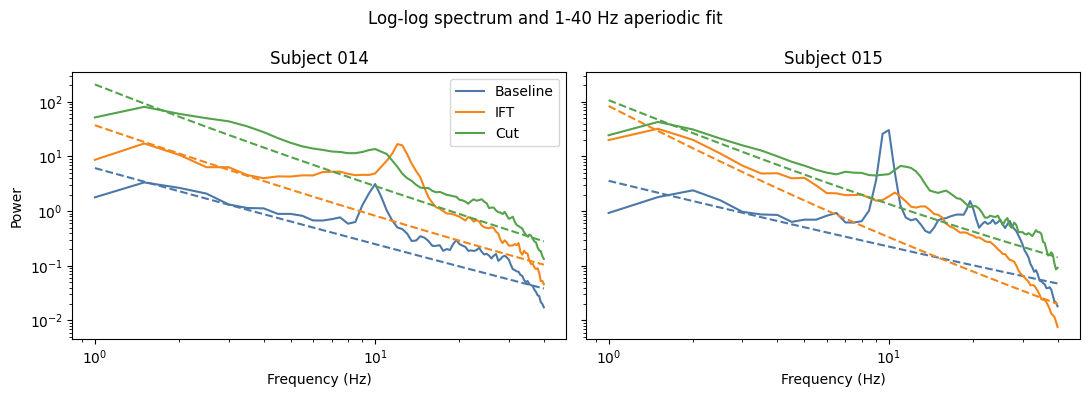

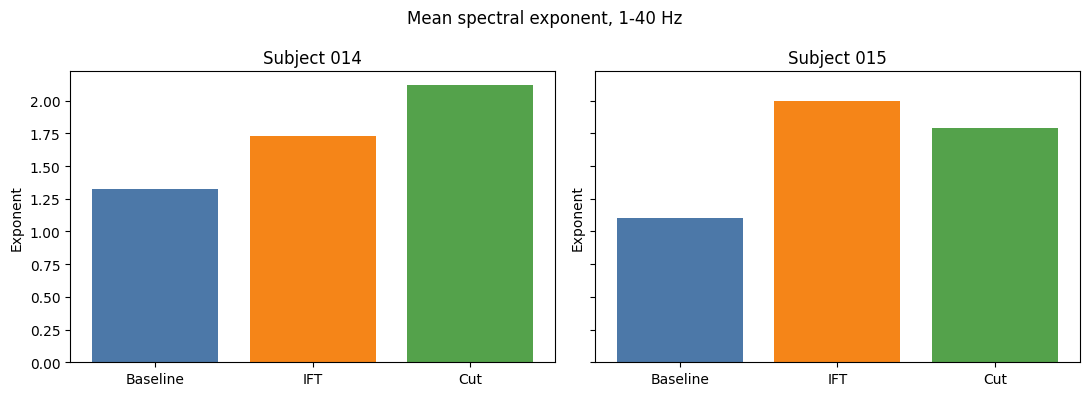

In [14]:
exponents, aperiodic = eeg.spectral_exponent(spectra)
exponent_table = (
    exponents.groupby(["subject_id", "condition", "frequency_range"], as_index=False)["exponent"].mean()
)
exponent_table = exponent_table.pivot(
    index=["subject_id", "condition"], columns="frequency_range", values="exponent"
)[["1-20 Hz", "1-40 Hz", "20-40 Hz"]].round(3)
display(exponent_table)

mean_curve = aperiodic.groupby(
    ["subject_id", "condition", "frequency"], as_index=False
)[["mean_power", "aperiodic_power"]].mean()
fig, axes = plt.subplots(1, 2, figsize=(11, 4), sharey=True)
for ax, subject in zip(axes, ["014", "015"]):
    for condition in condition_order:
        part = mean_curve[(mean_curve["subject_id"] == subject) & (mean_curve["condition"] == condition)]
        color = condition_colors[condition]
        ax.loglog(part["frequency"], part["mean_power"], color=color, label=condition)
        ax.loglog(part["frequency"], part["aperiodic_power"], color=color, linestyle="--")
    ax.set_title(f"Subject {subject}")
    ax.set_xlabel("Frequency (Hz)")
axes[0].set_ylabel("Power")
axes[0].legend()
fig.suptitle("Log-log spectrum and 1-40 Hz aperiodic fit")
fig.tight_layout()

mean_exponent = exponents[exponents["frequency_range"] == "1-40 Hz"]
mean_exponent = mean_exponent.groupby(["subject_id", "condition"], as_index=False)["exponent"].mean()
fig, axes = plt.subplots(1, 2, figsize=(11, 4), sharey=True)
for ax, subject in zip(axes, ["014", "015"]):
    part = mean_exponent[mean_exponent["subject_id"] == subject].set_index("condition").loc[condition_order]
    ax.bar(condition_order, part["exponent"], color=[condition_colors[name] for name in condition_order])
    ax.set_title(f"Subject {subject}")
    ax.set_ylabel("Exponent")
fig.suptitle("Mean spectral exponent, 1-40 Hz")
fig.tight_layout()


On the full 1–40 Hz range, the mean exponent is steeper after Baseline in both subjects. For 014 it rises from 1.325 at Baseline to 1.733 at IFT and 2.118 at Cut. For 015 it rises from 1.100 at Baseline to 1.995 at IFT, then is 1.790 at Cut. Every channel's 1–40 Hz exponent is positive: the smallest Baseline value is 0.654, on a 015 channel, and the largest Cut value is 2.533, on a 014 channel.

The split ranges do not tell the same story. The 20–40 Hz exponents are much steeper, about 3.7 to 5.6, which is where the low-pass edge of the 1–40 Hz filter can pull the slope down. The 1–20 Hz exponents are shallower. In 015 Baseline the channel mean is only 0.028, and 9 of the 16 channels are negative. That short range contains the large alpha peak, so the aperiodic fit is not a clean description of the slow fall. The 1–40 Hz fit is the main result. Median R-squared is 0.966 for 1–40 Hz, 0.947 for 1–20 Hz, and 0.988 for 20–40 Hz.

### 5.4 Lempel-Ziv Complexity

Lempel-Ziv complexity asks how much a sequence can be compressed. Each accepted epoch is turned into a binary sequence by marking samples above that epoch's own mean as 1. `antropy.lziv_complexity` then normalizes by n / log2(n), the usual length correction. The values below are averaged across epochs. A higher value means a more irregular binary pattern.

This is not PCI. The mean threshold is a choice for this project, and the result is not a consciousness score.

,subject_id,condition,lzc
0,014,Baseline,0.291
1,014,Cut,0.212
2,014,IFT,0.261
3,015,Baseline,0.300
4,015,Cut,0.267
5,015,IFT,0.246


Text(0.5, 0.98, 'Lempel-Ziv complexity by channel')

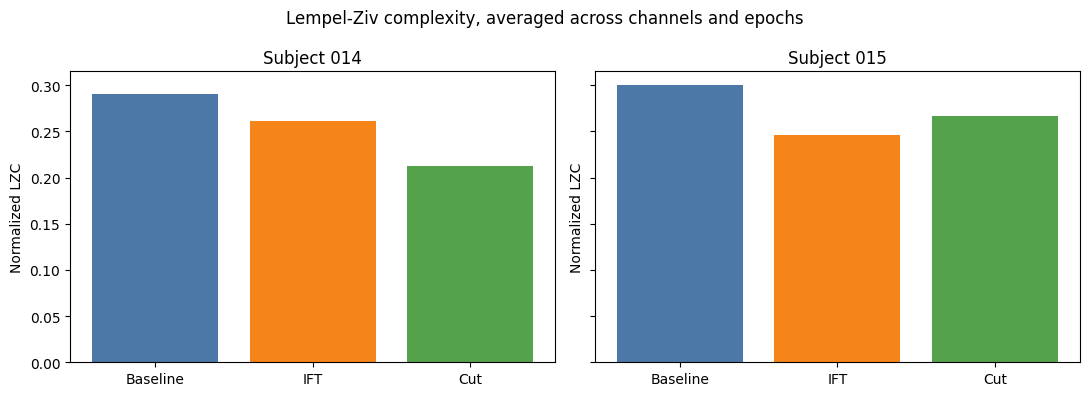

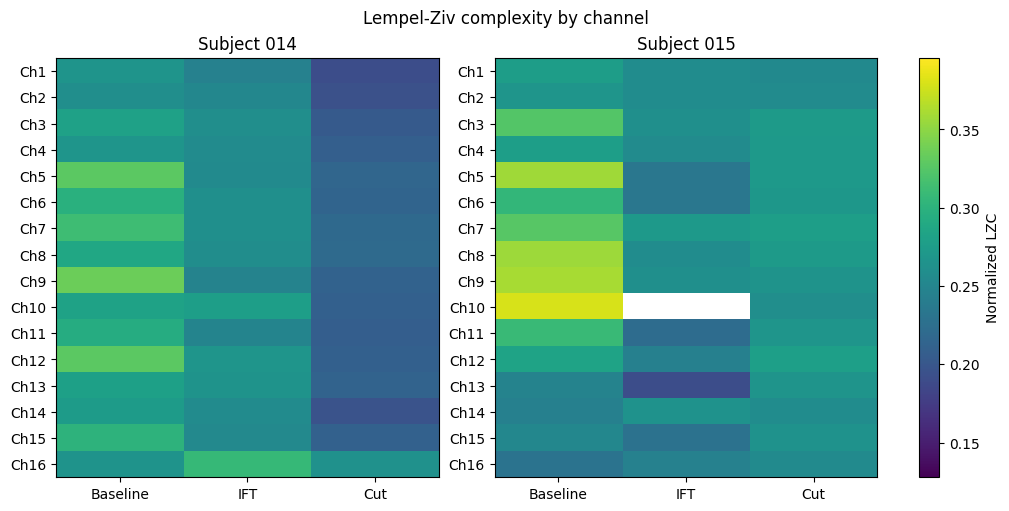

In [15]:
lzc = eeg.lempel_ziv_complexity(analysis_epochs)
lzc_summary = lzc.groupby(["subject_id", "condition"], as_index=False)["lzc"].mean()
lzc_summary["lzc"] = lzc_summary["lzc"].round(3)
display(lzc_summary)

fig, axes = plt.subplots(1, 2, figsize=(11, 4), sharey=True)
for ax, subject in zip(axes, ["014", "015"]):
    part = lzc_summary[lzc_summary["subject_id"] == subject].set_index("condition").loc[condition_order]
    ax.bar(condition_order, part["lzc"], color=[condition_colors[name] for name in condition_order])
    ax.set_title(f"Subject {subject}")
    ax.set_ylabel("Normalized LZC")
fig.suptitle("Lempel-Ziv complexity, averaged across channels and epochs")
fig.tight_layout()

shared_scale = (lzc["lzc"].min(), lzc["lzc"].max())
fig, axes = plt.subplots(1, 2, figsize=(10, 5), layout="constrained")
for ax, subject in zip(axes, ["014", "015"]):
    part = lzc[lzc["subject_id"] == subject]
    table = part.groupby(["channel", "condition"])["lzc"].mean().unstack("condition")[condition_order]
    table = table.reindex(sorted(table.index, key=lambda name: int(name[2:])))
    image = ax.imshow(table.to_numpy(), aspect="auto", vmin=shared_scale[0], vmax=shared_scale[1], cmap="viridis")
    ax.set_xticks(range(len(condition_order)), condition_order)
    ax.set_yticks(range(len(table)), table.index)
    ax.set_title(f"Subject {subject}")
fig.colorbar(image, ax=axes, label="Normalized LZC")
fig.suptitle("Lempel-Ziv complexity by channel")


Mean normalized LZC is lower than Baseline in every later recording. For 014 it falls from 0.291 at Baseline to 0.261 at IFT and 0.212 at Cut. For 015 it falls from 0.300 at Baseline to 0.246 at IFT, then is 0.267 at Cut. The channel heatmap shows the same direction on most channels: Baseline is the more irregular pattern, and 014 Cut is the most regular of the six recordings. The drop is a description of these epochs, not a claim that complexity measures the depth of anesthesia.

### 5.5 Fano Factor of Event Counts

The Fano factor used here is not the variance of the raw EEG divided by its mean. Inside each epoch, every channel is z-scored. An event starts when the absolute z-score crosses 2. Samples that stay beyond 2 inside the same excursion are not counted again. Event starts are added across the kept channels in bins of 8 ms (4 samples). The Fano factor is the variance of those bin counts divided by their mean, using the population variance. It is NaN if an epoch has no events. None of the accepted epochs had a mean count of zero.

The threshold and the bin width are project choices. Counting an absolute crossing, rather than a signed one, is also a project choice. The idea of summarizing event counts with a Fano factor follows Maschke et al. (2024). The trace shows the first 2 seconds of the first accepted epoch so that individual bins can be seen. The bars average the Fano factor across all accepted epochs.

,subject_id,condition,fano_factor
0,014,Baseline,1.621
1,014,Cut,1.890
2,014,IFT,1.967
3,015,Baseline,2.003
4,015,Cut,1.996
5,015,IFT,1.784


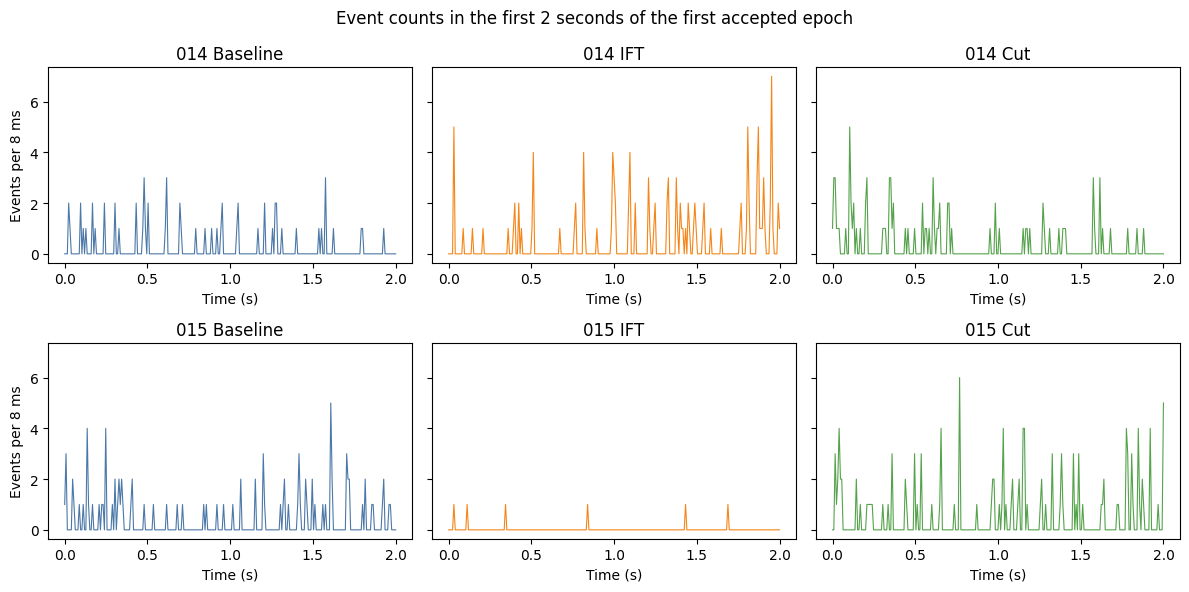

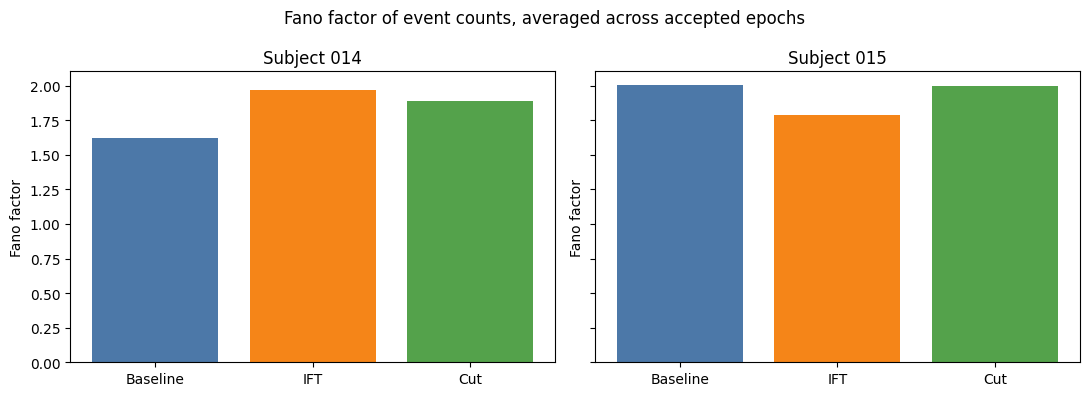

In [16]:
fano, event_counts = eeg.fano_factor(analysis_epochs)
fano_summary = fano.groupby(["subject_id", "condition"], as_index=False)["fano_factor"].mean()
fano_summary["fano_factor"] = fano_summary["fano_factor"].round(3)
display(fano_summary)

fig, axes = plt.subplots(2, 3, figsize=(12, 6), sharey=True)
for row, subject in enumerate(["014", "015"]):
    for column, condition in enumerate(condition_order):
        ax = axes[row, column]
        part = event_counts[
            (event_counts["subject_id"] == subject) & (event_counts["condition"] == condition)
        ]
        first = part["start_sample"].min()
        window = part[(part["start_sample"] == first) & (part["time_seconds"] <= 2)]
        ax.plot(window["time_seconds"], window["event_count"], color=condition_colors[condition], linewidth=0.8)
        ax.set_title(f"{subject} {condition}")
        ax.set_xlabel("Time (s)")
axes[0, 0].set_ylabel("Events per 8 ms")
axes[1, 0].set_ylabel("Events per 8 ms")
fig.suptitle("Event counts in the first 2 seconds of the first accepted epoch")
fig.tight_layout()

fig, axes = plt.subplots(1, 2, figsize=(11, 4), sharey=True)
for ax, subject in zip(axes, ["014", "015"]):
    part = fano_summary[fano_summary["subject_id"] == subject].set_index("condition").loc[condition_order]
    ax.bar(condition_order, part["fano_factor"], color=[condition_colors[name] for name in condition_order])
    ax.set_title(f"Subject {subject}")
    ax.set_ylabel("Fano factor")
fig.suptitle("Fano factor of event counts, averaged across accepted epochs")
fig.tight_layout()


The mean Fano factor stays near 2 and does not move in the same direction in the two subjects. For 014 it is 1.621 at Baseline, 1.967 at IFT, and 1.890 at Cut. For 015 it is 2.003 at Baseline, 1.784 at IFT, and 1.996 at Cut. A value near 1 would mean the bin counts vary about as much as a Poisson process with the same mean. These recordings sit above that, so the event counts are more clustered than a Poisson process, in every condition. The condition difference is small next to that shared level, and it is not consistent across the two subjects.

### 5.6 Within-Subject Comparison

Each row below is one recording. The exponent is the 1–40 Hz channel mean. LZC and the Fano factor are means across the accepted epochs. Epochs from the same file are repeated pieces of one recording, so they are not extra subjects. With two people, there is no population test.

In [17]:
comparison = readiness[["subject_id", "condition", "status", "n_usable_epochs"]].copy()
comparison = comparison.merge(
    dominant_band.rename(columns={"band": "dominant_band", "relative_power": "dominant_relative_power"}),
    on=["subject_id", "condition"],
)
comparison = comparison.merge(
    mean_exponent.rename(columns={"exponent": "exponent_1_40"}),
    on=["subject_id", "condition"],
)
comparison = comparison.merge(lzc.groupby(["subject_id", "condition"], as_index=False)["lzc"].mean(), on=["subject_id", "condition"])
comparison = comparison.merge(
    fano.groupby(["subject_id", "condition"], as_index=False)["fano_factor"].mean(),
    on=["subject_id", "condition"],
)
comparison[["dominant_relative_power", "exponent_1_40", "lzc", "fano_factor"]] = comparison[
    ["dominant_relative_power", "exponent_1_40", "lzc", "fano_factor"]
].round(3)
comparison


,subject_id,condition,status,n_usable_epochs,dominant_band,dominant_relative_power,exponent_1_40,lzc,fano_factor
0,014,Baseline,READY,3,Alpha,0.349,1.325,0.291,1.621
1,014,IFT,READY,3,Alpha,0.354,1.733,0.261,1.967
2,014,Cut,PARTIAL,17,Delta,0.418,2.118,0.212,1.890
3,015,Baseline,READY,3,Alpha,0.559,1.100,0.300,2.003
4,015,IFT,READY,10,Delta,0.384,1.995,0.246,1.784
5,015,Cut,PARTIAL,17,Alpha,0.333,1.790,0.267,1.996


In subject 014, Baseline and IFT are both READY and both led by alpha, at 0.349 and 0.354. From Baseline to IFT the 1–40 Hz exponent rises from 1.325 to 1.733, LZC falls from 0.291 to 0.261, and the Fano factor rises from 1.621 to 1.967. Cut is different in the spectrum and in complexity: delta becomes the largest band at 0.418, the exponent reaches 2.118, and LZC reaches its lowest value, 0.212. That Cut description uses 17 epochs. Thirteen other blocks were removed because Ch16 had too much provisional imputation, so the Cut average does not represent the whole 300 seconds.

In subject 015, Baseline is READY and strongly alpha, at 0.559, with the shallowest 1–40 Hz exponent, 1.100, and the highest LZC, 0.300. IFT is also READY, but the largest band becomes delta at 0.384, the exponent rises to 1.995, and LZC falls to 0.246. Cut moves back toward alpha, at 0.333, with an exponent of 1.790 and LZC of 0.267, between the Baseline and IFT values. Only 17 Cut epochs passed. Long gaps that were left missing broke the rest of the file into stretches too short to use.

The two subjects do not follow one shared pattern. Both show a steeper 1–40 Hz spectrum and a lower LZC away from Baseline, but the condition at which the slow band takes over is Cut for 014 and IFT for 015. The Fano factor does not rank the conditions in the same order. These are descriptions of two recordings at each stage.

### 5.7 Limits of This Analysis

Only two subjects are available. A difference between Baseline, IFT, and Cut is a within-subject description. It is not evidence about surgical patients in general, and the epochs are not independent participants.

Step 3 still affects these numbers. Medium gaps were filled with PCHIP and marked provisional. The 5% rule removes an epoch when that fill is large, which is why 014 Cut loses 13 epochs on Ch16, but smaller provisional fills remain inside accepted epochs. 015 Cut still has long gaps left as NaN. Those gaps, together with the 17 stretches that were too short to filter, are why 27 stretches produce no epoch.

Step 4 also shapes every metric. The 1–40 Hz filter attenuates the drift below 1 Hz and the activity above 40 Hz before the spectrum, the complexity, and the event counts are computed. The steep 20–40 Hz exponents should be read with that filter edge in mind. Lempel-Ziv complexity in this notebook is not PCI, and the spectral exponent is not a measure of consciousness.